<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta4_g%C3%B6rev5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

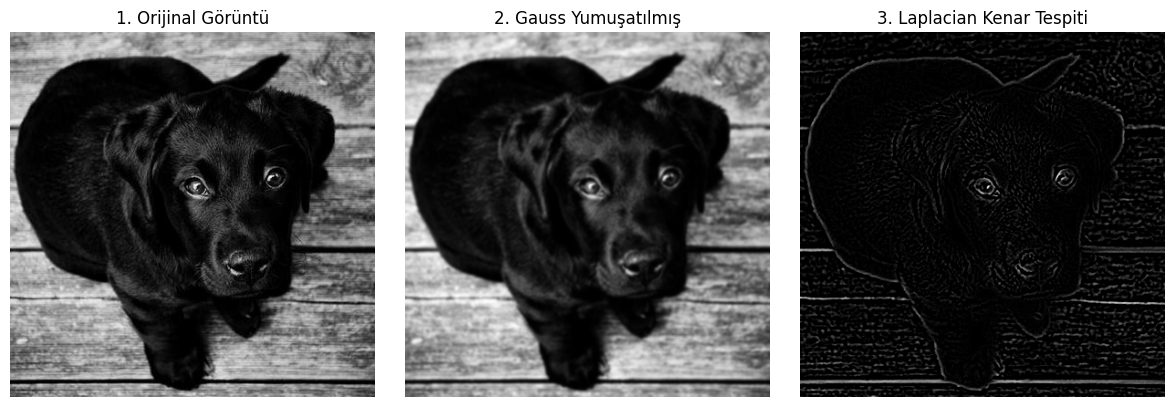

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# 1. Test için örnek bir görüntü indirelim
url = 'https://picsum.photos/id/237/400/400'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_GRAYSCALE)

# 2. Gauss Filtresi ile Görüntüyü Hafif Yumuşatma
blurred_img = cv2.GaussianBlur(img, (5, 5), 0)

# 3. 3x3 Laplacian Çekirdeği (Merkez pozitif, çevreleyenler negatif versiyonu)
laplacian_kernel = np.array([
    [0,  1, 0],
    [1, -4, 1],
    [0,  1, 0]
], dtype=np.float32)

# Alternatif yaygın Laplacian çekirdeği (köşeleri de dahil eden):
# laplacian_kernel = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], dtype=np.float32)

# 4. Filtreyi görüntü üzerinde uygulama
filtered_laplacian = cv2.filter2D(blurred_img, -1, laplacian_kernel)
# Laplacian sonuçlarında negatif değerler olabileceği için mutlak değer alıp görselleştirmek iyi olur:
filtered_laplacian_abs = cv2.convertScaleAbs(filtered_laplacian)

# 5. Sonuçları Görselleştirme
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('1. Orijinal Görüntü')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(blurred_img, cmap='gray')
plt.title('2. Gauss Yumuşatılmış')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(filtered_laplacian_abs, cmap='gray')
plt.title('3. Laplacian Kenar Tespiti')
plt.axis('off')

plt.tight_layout()
plt.show()

Kenar Bulma Yöntemleri Karşılaştırması: Sobel, Prewitt ve Laplacian
Bu çalışmada, görüntü işleme dersinde öğrendiğimiz üç temel kenar bulma filtresini (Sobel, Prewitt ve Laplacian) kendi aralarında kıyasladım. Hepsini uygulamadan önce resimdeki ufak pürüzler kenar sanılmasın diye Gauss filtresiyle hafifçe yumuşattım.

1. Temel Farklar Neler?
Prewitt ve Sobel (Birinci Derece Türev): Bu ikisi yönlü çalışır. Yani resmin hem yatayındaki hem de dikeyindeki değişimlere ayrı ayrı bakarlar. Prewitt her piksele eşit değer verirken, Sobel ortadaki piksellere 2 kat daha fazla ağırlık verir. Bu yüzden Sobel gürültüleri biraz daha iyi bastırır ve kenarları daha net çıkarır.

Laplacian (İkinci Derece Türev): Sobel ve Prewitt'ten farklı olarak yönlü değildir, resmin her yöndeki ani değişimlerini tek seferde yakalar. İkinci derece türev aldığı için parlaklığın en hızlı değiştiği yerleri (çizgilerin ortasını ve sıfır geçişlerini) bulur.

2. Hangisi Nasıl Sonuç Veriyor?
Sobel ve Prewitt: Kenarları kalın çizgiler halinde ve yöne göre (yatay/dikey) ayrı ayrı gösterir. Genellikle nesnelerin ana hatlarını çıkartmak için çok idealdir.

Laplacian: Resimdeki tüm ince çizgileri, detayları ve ani parlaklık değişimlerini her yönden aynı anda yakalar. Fakat büyük bir dezavantajı vardır: Gürültüye karşı aşırı hassastır. Önüne Gauss filtresi koysak bile bazen resimdeki minik detayları bile kenar gibi parlatabilir ve çok ince, keskin hatlar oluşturur.